# Playground — CNN 1D (Guilherme)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb)

**Notebook autossuficiente para experimentar à vontade.** Tudo está aqui dentro (dados, MFCC, modelo, treino,
avaliação e latência) e nada é importado das pastas do repositório. Dá para mudar qualquer linha sem quebrar o
código de ninguém.

Como usar:
1. Abra no Colab (Ambiente de execução → Alterar tipo → GPU). Para guardar as alterações:
   **Arquivo → Salvar uma cópia no GitHub** ou baixe o `.ipynb` e substitua este arquivo.
2. Implemente a `CNN1D` na seção **4. Modelo** (os pontos marcados com `TODO`).
3. Use `fracao < 1` nos hiperparâmetros para iterar rápido; para números de verdade, `fracao = 1.0`.
4. Quando a arquitetura estiver definida, siga a seção **10. Levando para o repositório**.

Para os números serem comparáveis com a bancada (`dados/`, `treino/`, `avaliacao/`), este notebook usa as mesmas
regras: o split oficial por locutor, o mesmo MFCC, a mesma montagem da tarefa de 12 classes e o mesmo loop de
treino (AdamW + OneCycle + label smoothing). O cache de MFCC também é o mesmo arquivo usado pela bancada.

## 1. Setup

No Colab, o Google Drive é montado: o `.tar.gz` do GSC, o cache de MFCC e os resultados ficam em
`MyDrive/kws-borda/` e sobrevivem ao fim da sessão. Os áudios são extraídos no disco local (`/content/data`),
porque ler 100 mil arquivos direto do Drive é muito lento.

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchaudio
import soundfile as sf

#Monta o Google Drive para o download e o cache do MFCC sobreviverem ao fim da sessão
from google.colab import drive
drive.mount('/content/drive')

PASTA_DRIVE = '/content/drive/MyDrive/kws-borda'
PASTA_DOWNLOADS = os.path.join(PASTA_DRIVE, 'downloads')
PASTA_CACHE = os.path.join(PASTA_DRIVE, 'cache')
#Áudios extraídos no disco local do Colab: ler 100 mil arquivos direto do Drive é muito lento
PASTA_DADOS = '/content/data/gsc'

os.makedirs(PASTA_DOWNLOADS, exist_ok=True)
os.makedirs(PASTA_CACHE, exist_ok=True)
os.makedirs(PASTA_DADOS, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda


In [52]:
import psutil, shutil

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'nenhuma')
!nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv

ram = psutil.virtual_memory()
print(f'RAM total: {ram.total/1e9:.1f} GB | livre: {ram.available/1e9:.1f} GB')
print(f'Disco: {shutil.disk_usage("/content").total/1e9:.0f} GB | CPUs: {os.cpu_count()}')

GPU: Tesla T4
name, memory.total [MiB], memory.used [MiB]
Tesla T4, 15360 MiB, 381 MiB
RAM total: 13.6 GB | livre: 3.3 GB
Disco: 253 GB | CPUs: 2


## 2. Hiperparâmetros

Um único dicionário controla o experimento. Os hiperparâmetros **da arquitetura** (canais, camadas, kernel...)
ficam na seção 4, junto do modelo.

MFCC: o padrão é 40 coeficientes × 101 janelas (janela de 30 ms, passo de 10 ms). Para a entrada 8x menor do
artigo Hello Edge, use `n_mfcc=10, janela_ms=40, passo_ms=20, center=False` (10 × 49).

In [ ]:
hyperparameters = {
    #Experimento
    'fracao': 1,              #fração do TREINO usada (1.0 = tudo). Val e teste são sempre completos
    'seeds':[0, 1, 2],                # [0, 1, 2],      #seeds da varredura
    'margem_pp': 2.0,        #critério do projeto, até 2 p.p. abaixo do baseline 

    #MFCC
    'sample_rate': 16000,       #o GSC é gravado a 16 kHz: 1 s = 16000 amostras
    'n_mfcc': 40,               #coeficientes por janela (vão virar os CANAIS da CNN 1D)
    'janela_ms': 30,            #tamanho de cada fatia de audio que vira uma coluna da tabela
    'passo_ms': 10,             #quanto a janela desliza pela matriz do audio
    'n_mels': 40,               #bandas Mel (finas nos graves, largas nos agudos, como o ouvido); o MFCC sai delas, n_mfcc <= n_mels
    'f_min': 20,                #abaixo de 20 Hz não é fala
    'f_max': 7600,              #limite físico é 8 kHz (metade de 16 kHz, Nyquist); para um pouco antes porque perto de 8 kHz o filtro da gravação distorce
    'center': True,             #para representar as bordas melhor
    'normalizacao': 'global',   #'global': média/desvio por coeficiente medidos no treino | 'por_amostra': cada áudio com a própria média/desvio (robusto a microfone, mas infla o ruído do silêncio)
    'spec_augment': True,       #zera faixas de tempo e de coeficientes no treino (regulariza)

    #Treino
    'epocas': 20,
    'batch_size': 128,
    'learning_rate': 0.003,     
    'weight_decay': 0.01,       #penaliza pesos grandes (AdamW)
    'label_smoothing': 0.1,    
    'seed': 0,

    #Arquitetura (CNN 1D)
    'canais': 64,               
}

## 3. Dados — Google Speech Commands v2

### 3.1 Download e extração
2,3 GB. Na primeira vez baixa para o Drive; nas próximas sessões só extrai (1–2 min).

In [3]:
URL_GSC = 'https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz'
ARQUIVO_TAR = os.path.join(PASTA_DOWNLOADS, 'speech_commands_v0.02.tar.gz')

#Baixa só na primeira vez: nas próximas sessões o .tar.gz já está no Drive
if not os.path.exists(ARQUIVO_TAR):
    #Baixa com nome provisório e só renomeia no fim: se a conexão cair no meio,
    #não fica um arquivo pela metade com o nome final (que o if acima acharia que está pronto)
    !wget -q --show-progress -O {ARQUIVO_TAR}.parcial {URL_GSC}
    !mv {ARQUIVO_TAR}.parcial {ARQUIVO_TAR}

#Extrai no disco local. O /content apaga ao fim da sessãos
if not os.path.exists(os.path.join(PASTA_DADOS, 'testing_list.txt')):
    !tar -xzf {ARQUIVO_TAR} -C {PASTA_DADOS}

print('GSC em', PASTA_DADOS)

GSC em /content/data/gsc


### 3.2 Classes e split

In [4]:
#As 35 palavras do GSC v2, em ordem alfabética.
#A ordem NÃO pode mudar entre treino e avaliação, senão o índice 0 deixa de ser 'backward' e as métricas saem erradas
CLASSES_GSC = [
    'backward', 'bed', 'bird', 'cat', 'dog', 'down', 'eight', 'five', 'follow', 'forward',
    'four', 'go', 'happy', 'house', 'learn', 'left', 'marvin', 'nine', 'no', 'off',
    'on', 'one', 'right', 'seven', 'sheila', 'six', 'stop', 'three', 'tree', 'two',
    'up', 'visual', 'wow', 'yes', 'zero',
]


def rotulo(rel, classes):
    """Caminho relativo -> índice da classe na lista `classes`. Ex.: 'cat/x.wav' -> 3."""
    palavra = rel.split('/')[0]   #a pasta é a classe, como o train/<classe>/ do TinyImageNet
    return classes.index(palavra)


def listar_35(raiz):
    """Separa os arquivos das 35 palavras em treino/val/teste usando as listas OFICIAIS do dataset."""

    with open(os.path.join(raiz, 'validation_list.txt'), 'r') as f:
        val = set(f.read().split())
    with open(os.path.join(raiz, 'testing_list.txt'), 'r') as f:
        teste = set(f.read().split())

    split = {'treino': [], 'val': [], 'teste': []}

    for classe in CLASSES_GSC:
        #sorted para a ordem ser sempre igual entre execuções
        for arquivo in sorted(os.listdir(os.path.join(raiz, classe))):
            rel = f'{classe}/{arquivo}'   #formato igual ao das listas oficiais

            if rel in val:
                split['val'].append(rel)
            elif rel in teste:
                split['teste'].append(rel)
            else:
                #o que não está em nenhuma das duas listas é treino
                split['treino'].append(rel)

    return split

In [5]:
#Conferencia
split = listar_35(PASTA_DADOS)

print({k: len(v) for k, v in split.items()})
print('total:', sum(len(v) for v in split.values()))  
print('exemplo:', split['treino'][0], '->', rotulo(split['treino'][0], CLASSES_GSC))   

#O ID do locutor é o que vem antes de '_nohash_' no nome do arquivo
def locutor(rel):
    return rel.split('/')[1].split('_nohash_')[0]

locutores = {k: {locutor(r) for r in v} for k, v in split.items()}
print('locutores no treino E no teste:', len(locutores['treino'] & locutores['teste']))   
print('locutores no treino E na val:  ', len(locutores['treino'] & locutores['val']))     

{'treino': 84843, 'val': 9981, 'teste': 11005}
total: 105829
exemplo: backward/0165e0e8_nohash_0.wav -> 0
locutores no treino E no teste: 0
locutores no treino E na val:   0


### 3.3 MFCC

Cada áudio de 1 s vira uma matriz `(n_mfcc, n_frames)`: para cada janela de tempo, coeficientes que resumem o
espectro na escala Mel. O MFCC de todo o dataset é calculado **uma vez** e salvo em cache.

In [6]:
N_AMOSTRAS = hyperparameters['sample_rate'] 


def ler_audio(caminho):
    """Lê um .wav do GSC e devolve um tensor (16000,), sempre com exatamente 1 s."""

    #dtype='float32' já entrega os valores em [-1, 1]
    #sf.read devolve (amostras, taxa_de_amostragem)
    wav, sr = sf.read(caminho, dtype='float32')
    wav = torch.from_numpy(wav)

    #Todo áudio precisa ter o mesmo tamanho para os batches empilharem (mesmo motivo do .convert('RGB')
    #no TinyImageNet: um item diferente quebra o batch)
    if len(wav) < N_AMOSTRAS:
        #Curto: completa com zeros (silêncio) no final
        return torch.nn.functional.pad(wav, (0, N_AMOSTRAS - len(wav)))

    #Longo (ou exato): corta no centro
    inicio = (len(wav) - N_AMOSTRAS) // 2
    return wav[inicio:inicio + N_AMOSTRAS]


def criar_extrator(hp):
    #Converte de milissegundos para número de amostras: 16 amostras por ms
    n_fft = int(hp['sample_rate'] * hp['janela_ms'] / 1000)   
    hop = int(hp['sample_rate'] * hp['passo_ms'] / 1000)    

    return torchaudio.transforms.MFCC(
        sample_rate=hp['sample_rate'], n_mfcc=hp['n_mfcc'],
        melkwargs=dict(n_fft=n_fft, win_length=n_fft, hop_length=hop, n_mels=hp['n_mels'],
                       f_min=hp['f_min'], f_max=hp['f_max'], center=hp['center']))


def calcular_n_frames(hp):
    n_fft = int(hp['sample_rate'] * hp['janela_ms'] / 1000)
    hop = int(hp['sample_rate'] * hp['passo_ms'] / 1000)

    if hp['center']:
        #Com enchimento nas bordas: uma janela a cada passo, contando os dois extremos (0, 10, ..., 1000 ms)
        return 1 + N_AMOSTRAS // hop
    else:
        #Sem enchimento: só cabem janelas inteiras dentro do áudio
        return 1 + (N_AMOSTRAS - n_fft) // hop

arquivo: down/017c4098_nohash_4.wav
waveform: (16000,) torch.float32
mfcc: (40, 101)
n_frames calculado: 101


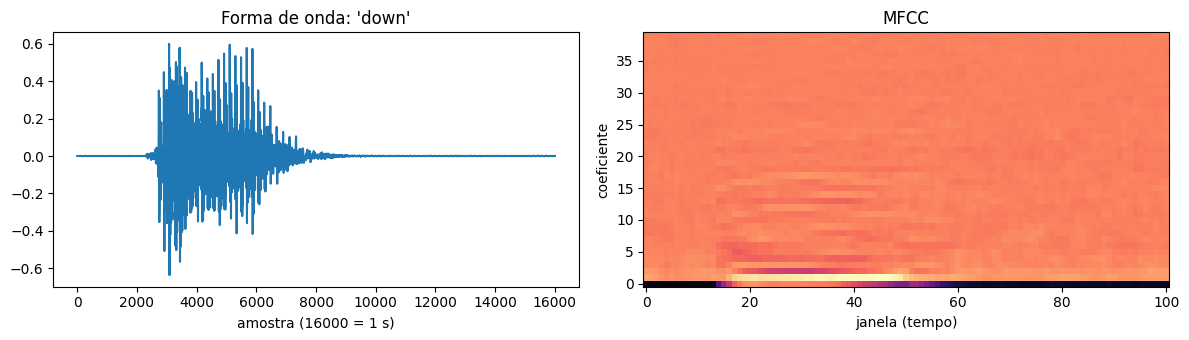

In [7]:
#Teste
extrator = criar_extrator(hyperparameters)
N_FRAMES = calcular_n_frames(hyperparameters)

rel = random.choice(split['treino'])
wav = ler_audio(os.path.join(PASTA_DADOS, rel))
mfcc = extrator(wav)

print('arquivo:', rel)
print('waveform:', tuple(wav.shape), wav.dtype)   
print('mfcc:', tuple(mfcc.shape))                
print('n_frames calculado:', N_FRAMES)            

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(wav.numpy())
axes[0].set_title(f"Forma de onda: '{rel.split('/')[0]}'")
axes[0].set_xlabel('amostra (16000 = 1 s)')

#origin='lower' põe o coeficiente 1 embaixo
axes[1].imshow(mfcc, aspect='auto', origin='lower', cmap='magma')
axes[1].set_title('MFCC')
axes[1].set_xlabel('janela (tempo)'); axes[1].set_ylabel('coeficiente')

plt.tight_layout(); plt.show()

In [8]:
from tqdm.auto import tqdm

In [9]:
def nome_cache(hp):
    """Identifica a combinação de parâmetros do MFCC: caches diferentes não se misturam."""
    if hp['center']:
        centro = 'c'
    else:
        centro = 'nc'

    return f"gsc35_{hp['n_mfcc']}x{calcular_n_frames(hp)}_{hp['janela_ms']}-{hp['passo_ms']}ms{centro}"


def extrair_mfcc(arquivos, caminho_cache, extrator, classes, batch=256):
    """MFCC de todos os arquivos (ou carrega do cache). Devolve (X, y)."""

    #Se já foi calculado em outra sessão, só carrega
    if os.path.exists(caminho_cache):
        return torch.load(caminho_cache)

    X, y = [], []

    #Não precisa de gradiente: o MFCC não tem pesos para aprender
    with torch.no_grad():
        for i in tqdm(range(0, len(arquivos), batch), desc=os.path.basename(caminho_cache)):
            lote = arquivos[i:i + batch]

            #Empilha 256 áudios -> (256, 16000) e converte todos de uma vez -> (256, 40, 101).
            #O extrator aceita batch, então é bem mais rápido que um áudio por vez
            audios = torch.stack([ler_audio(os.path.join(PASTA_DADOS, rel)) for rel in lote])
            X.append(extrator(audios))
            y += [rotulo(rel, classes) for rel in lote]

    X = torch.cat(X)          #lista de blocos (256, 40, 101) -> um tensor só (N, 40, 101)
    y = torch.tensor(y)       #lista de inteiros -> tensor (N,)

    torch.save((X, y), caminho_cache)
    return X, y

In [10]:
dados = {}
for nome_split, arquivos in split.items(): #Pega o treino, val e teste
    caminho = os.path.join(PASTA_CACHE, f"gsc_{nome_split}_{nome_cache(hyperparameters)}.pt")
    dados[nome_split] = extrair_mfcc(arquivos, caminho, extrator, CLASSES_GSC)

for nome_split, (X, y) in dados.items(): #verificar os shapes
    print(f'{nome_split:6s} X: {tuple(X.shape)}  y: {tuple(y.shape)}') #Audio, coeficiente MFCC (como se fosse os 3 canais RGB), Janela de tempo

#Quantos áudios cada palavra tem no treino. Vai importar quando formos escolher as melhores palavras
contagem = torch.bincount(dados['treino'][1], minlength=len(CLASSES_GSC))
print('áudios por classe no treino | min:', contagem.min().item(), '| max:', contagem.max().item())

treino X: (84843, 40, 101)  y: (84843,)
val    X: (9981, 40, 101)  y: (9981,)
teste  X: (11005, 40, 101)  y: (11005,)
áudios por classe no treino | min: 1256 | max: 3250


In [11]:
print(X[0].shape)                    #(40, 101)
print(X[0, :, 10].shape)             #(40,)
print(X[0, :5, 10])                  #os 5 primeiros coeficientes da janela 10
print(X.mean(dim=(0, 2))[:5])        #média dos 5 primeiros coeficientes no treino todo

torch.Size([40, 101])
torch.Size([40])
tensor([-197.8233,   50.3784,   43.8017,   35.5056,   24.2480])
tensor([-152.0904,   32.0921,    3.2896,    5.1118,   -2.4080])


### 3.4 Normalização, SpecAugment e DataLoaders

In [12]:
#Medido SÓ no treino. Validação e teste usam estas mesmas estatísticas
X_treino = dados['treino'][0]    

#dim=(0, 2) junta TODOS os áudios (dim 0) e TODAS as janelas (dim 2): sobra só a dim 1, os 40 coeficientes.
#keepdim=True mantém as dimensões com tamanho 1 -> (1, 40, 1), para a conta fazer broadcast
#O [0] tira a dimensão do batch -> (40, 1). Assim a mesma média serve para um batch (B, 40, 101)
#e para um áudio solto (40, 101), que é o caso da medição de latência
media = X_treino.mean(dim=(0, 2), keepdim=True)[0]    #(40, 1)
desvio = X_treino.std(dim=(0, 2), keepdim=True)[0]    #(40, 1)

print('media:', tuple(media.shape), '| desvio:', tuple(desvio.shape))   #esperado: (40, 1) (40, 1)
print('media dos 5 primeiros coef:', media[:5, 0])
print('desvio dos 5 primeiros coef:', desvio[:5, 0])

media: (40, 1) | desvio: (40, 1)
media dos 5 primeiros coef: tensor([-148.8547,   31.1035,    3.2355,    4.4442,   -2.4068])
desvio dos 5 primeiros coef: tensor([84.5502, 38.6861, 20.3911, 15.8932, 14.1767])


In [13]:
def normalizar(x, media, desvio):
    """Normaliza o MFCC (..., n_mfcc, n_frames)."""

    if media is None:
        #por_amostra: cada áudio usa a PRÓPRIA média e desvio ao longo do tempo
        #O 1e-6 evita dividir por zero num áudio perfeitamente constante
        return (x - x.mean(dim=-1, keepdim=True)) / (x.std(dim=-1, keepdim=True) + 1e-6)

    #global: (x - mean) / std
    return (x - media) / desvio

In [14]:
#Conferir
X_norm = normalizar(X_treino, media, desvio)
print('treino | média por coef:', X_norm.mean(dim=(0, 2))[:5])    #esperado: ~0
print('treino | desvio por coef:', X_norm.std(dim=(0, 2))[:5])    #esperado: ~1

X_val_norm = normalizar(dados['val'][0], media, desvio)
print('val    | média por coef:', X_val_norm.mean(dim=(0, 2))[:5])   #esperado: perto de 0, mas não exato
print('val    | desvio por coef:', X_val_norm.std(dim=(0, 2))[:5])   #esperado: perto de 1, mas não exato

del X_norm, X_val_norm   #libera ~1,5 GB de RAM

treino | média por coef: tensor([ 1.8087e-05,  2.4854e-06,  1.1373e-06, -9.7537e-08,  3.6865e-08])
treino | desvio por coef: tensor([1., 1., 1., 1., 1.])
val    | média por coef: tensor([-0.0257,  0.0350,  0.0013, -0.0100,  0.0165])
val    | desvio por coef: tensor([1.0029, 1.0016, 1.0106, 1.0158, 1.0014])


In [15]:
def spec_augment(x, max_tempo=10, max_coef=7):
    """x: (n_mfcc, n_frames) de UM áudio. Zera uma faixa de janelas e uma faixa de coeficientes."""

    #Trabalha numa CÓPIA. Sem isso, o x[...] = 0 apagaria o trecho direto no X guardado na memória,
    #e o áudio ficaria mutilado para sempre, em todas as épocas seguintes
    x = x.clone()
    n_coef, n_frames = x.shape

    #Com poucos coeficientes, zerar 7 apagaria quase tudo
    max_coef = min(max_coef, n_coef // 4)

    #Faixa no tempo
    #Largura sorteada de 0 a max_tempo janelas (o () pede um sorteio escalar; o .item() vira int do Python)
    t = torch.randint(0, max_tempo + 1, ()).item()
    #de 0 até o último ponto em que a faixa ainda cabe dentro das 101 janelas
    t0 = torch.randint(0, n_frames - t + 1, ()).item()
    x[:, t0:t0 + t] = 0     #zera todos os coeficientes nessas janelas

    #Faixa na frequência
    f = torch.randint(0, max_coef + 1, ()).item()
    f0 = torch.randint(0, n_coef - f + 1, ()).item()
    x[f0:f0 + f, :] = 0     #zera essas linhas em todas as janelas

    return x

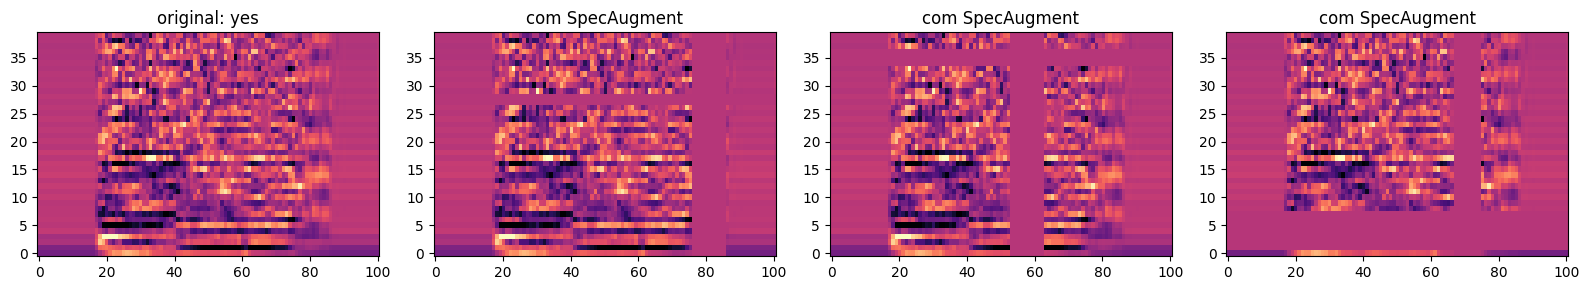

original intacto: True


In [16]:
i = random.randrange(len(dados['val'][1]))
x = normalizar(dados['val'][0][i], media, desvio)   
palavra = CLASSES_GSC[dados['val'][1][i]]

fig, axes = plt.subplots(1, 4, figsize=(16, 3))

#Mesma escala de cor (vmin/vmax) nos 4 gráficos
axes[0].imshow(x, aspect='auto', origin='lower', cmap='magma', vmin=-3, vmax=3)
axes[0].set_title(f'original: {palavra}')

#3 sorteios diferentes do mesmo áudio
for ax in axes[1:]:
    ax.imshow(spec_augment(x), aspect='auto', origin='lower', cmap='magma', vmin=-3, vmax=3)
    ax.set_title('com SpecAugment')

plt.tight_layout(); plt.show()

#Teste do clone: o original não pode ter sido alterado
x_antes = x.clone()
_ = spec_augment(x)
print('original intacto:', torch.equal(x, x_antes))   #esperado: True

In [17]:
class DatasetMFCC(torch.utils.data.Dataset):

    def __init__(self, X, y, media, desvio, aumentar=False):
        super().__init__()

        #Normaliza tudo de uma vez aqui, e não um áudio por __getitem__
        self.X = normalizar(X, media, desvio)
        self.y = y
        self.aumentar = aumentar    #SpecAugment ligado ou desligado

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        """Retorna (mfcc: torch.Tensor (40, 101), label: int)."""
        x = self.X[idx]

        #Aumento de dados sorteado a CADA vez que o áudio é pedido: na época seguinte as faixas mudam
        if self.aumentar:
            x = spec_augment(x)

        return x, self.y[idx]

In [18]:
!pip install pytorch_lightning -q
import pytorch_lightning as pl

In [19]:
from torch.utils.data import DataLoader

In [20]:
class DataModuleGSC(pl.LightningDataModule):
    def __init__(self, hparams, dados):
        super().__init__()

        #Passa só o dicionário: os tensores de `dados` ficam fora dos hparams
        self.save_hyperparameters(hparams)
        self.dados = dados

    def setup(self, stage=None):
        X_treino, y_treino = self.dados['treino']

        #Fração do treino. Val e teste são sempre completos
        if self.hparams.fracao < 1:
            #Semente fixa: a mesma fração dá sempre os mesmos exemplos
            gerador = torch.Generator().manual_seed(0)
            idx = torch.randperm(len(y_treino), generator=gerador)[:int(len(y_treino) * self.hparams.fracao)]
            X_treino, y_treino = X_treino[idx], y_treino[idx]

        #Estatísticas medidas SÓ no treino
        #A validação e o teste usam as estatísticas do TREINO
        if self.hparams.normalizacao == 'global':
            self.media = X_treino.mean(dim=(0, 2), keepdim=True)[0]
            self.desvio = X_treino.std(dim=(0, 2), keepdim=True)[0]
        else:
            #por_amostra: nada a guardar
            self.media = None
            self.desvio = None

        #SpecAugment só no treino 
        self.train = DatasetMFCC(X_treino, y_treino, self.media, self.desvio,
                                 aumentar=self.hparams.spec_augment)
        self.val = DatasetMFCC(*self.dados['val'], self.media, self.desvio)
        self.test = DatasetMFCC(*self.dados['teste'], self.media, self.desvio)

    def train_dataloader(self):
        return DataLoader(self.train, batch_size=self.hparams.batch_size, shuffle=True)

    def val_dataloader(self):
        return DataLoader(self.val, batch_size=self.hparams.batch_size, shuffle=False)

    def test_dataloader(self):
        return DataLoader(self.test, batch_size=self.hparams.batch_size, shuffle=False)

treino  16968 áudios | 133 batches
val      9981 áudios |  78 batches
teste   11005 áudios |  86 batches
shape do batch: torch.Size([128, 40, 101])
dtype: torch.float32
labels: [18, 19, 19, 6, 3, 4, 11, 2]
fração de zeros exatos | treino: 0.14033493399620056 | val: 0.0


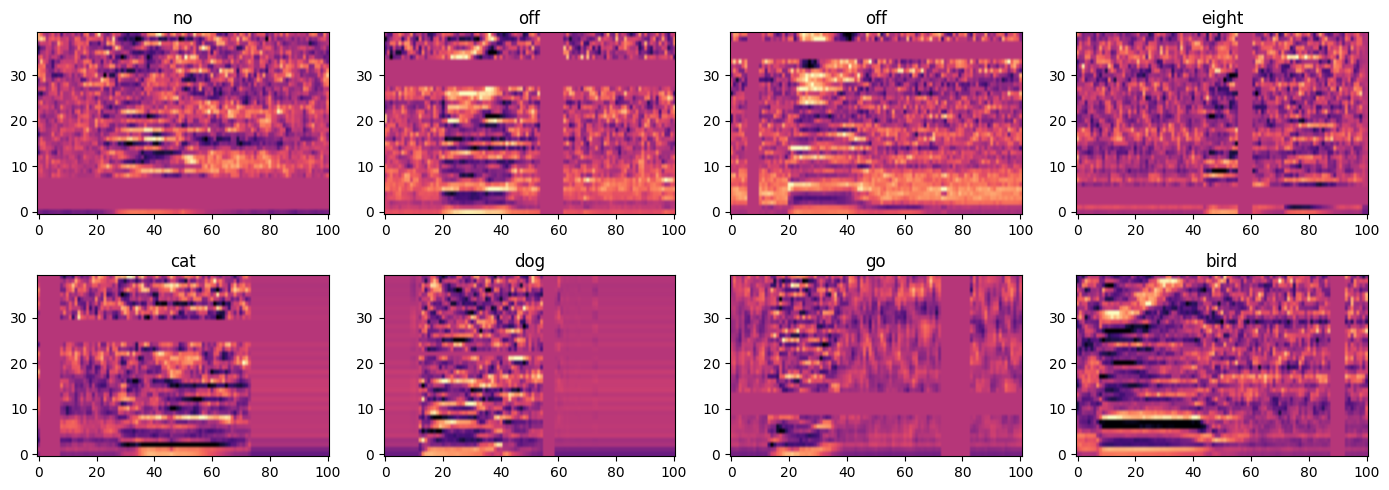

In [21]:

datamodule = DataModuleGSC(hyperparameters, dados)
datamodule.setup()
train_dl = datamodule.train_dataloader()
val_dl = datamodule.val_dataloader()
test_dl = datamodule.test_dataloader()

for nome_split, loader in [('treino', train_dl), ('val', val_dl), ('teste', test_dl)]:
    print(f'{nome_split:6s} {len(loader.dataset):6d} áudios | {len(loader):3d} batches')
#esperado com fracao=0.2: treino 16968 | 133 batches, val 9981 | 78, teste 11005 | 86

xb, yb = next(iter(train_dl))
print('shape do batch:', xb.shape)       #esperado: (128, 40, 101)
print('dtype:', xb.dtype)                #esperado: torch.float32
print('labels:', yb[:8].tolist())

#SpecAugment só no treino: o treino deve ter zeros exatos (as faixas), a validação não
xv, yv = next(iter(val_dl))
print('fração de zeros exatos | treino:', (xb == 0).float().mean().item(),
      '| val:', (xv == 0).float().mean().item())      #esperado: treino > 0, val = 0

#Para VER o que vai entrar na rede
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(xb[i], aspect='auto', origin='lower', cmap='magma', vmin=-3, vmax=3)
    ax.set_title(CLASSES_GSC[yb[i]])
plt.tight_layout(); plt.show()

In [22]:
print('hparams.spec_augment:', datamodule.hparams.spec_augment)     
print('train.aumentar:', datamodule.train.aumentar)                  

#Soma os zeros exatos de 20 áudios do treino (um só pode dar 0 por sorteio, a largura pode sair 0)
zeros = sum((datamodule.train[i][0] == 0).sum().item() for i in range(20))
print('zeros em 20 áudios do treino:', zeros)                        #esperado: > 0

hparams.spec_augment: True
train.aumentar: True
zeros em 20 áudios do treino: 11342


## 4. Modelo

**Contrato**:
- entrada `x`: `(B, n_mfcc, n_frames)`, o MFCC normalizado;
- saída: logits `(B, n_classes)`;
- a última camada se chama `self.head`;
- o `__init__` recebe `n_classes, n_mfcc, n_frames` e, depois, os hiperparâmetros da arquitetura.

In [23]:
class CNN1D(torch.nn.Module):
    """
    CNN 1D: convolução ao longo do TEMPO.
    Os n_mfcc coeficientes são tratados como CANAIS e o filtro desliza só no eixo temporal (as 101 janelas).
    Cada filtro aprende um padrão espectral que se repete no tempo.
    """
    #n_frames não é usado: o pooling global aceita qualquer comprimento.
    def __init__(self, n_classes, n_mfcc=40, n_frames=101, canais=64, kernel_size=3):
        super().__init__()

        k = kernel_size
        p = k // 2   #Padding para o tempo não encolher na borda

        #x chega como (B, n_mfcc, n_frames): os 40 coeficientes já são os canais que o nn.Conv1d espera,
        #então não precisa de permute

        #Bloco 1: 101 -> 101 (stride 1, mantém o tempo)
        #40,64
        self.conv1 = torch.nn.Conv1d(n_mfcc, canais, k, stride=1, padding=p, bias=False) #o BatchNorm anula qualquer bias
        self.bn1   = torch.nn.BatchNorm1d(canais)

        #Blocos 2, 3 e 4: stride 2, o tempo cai pela metade a cada bloco
        #64,64
        self.conv2 = torch.nn.Conv1d(canais, canais, k, stride=2, padding=p, bias=False)   # 101 -> 51
        self.bn2   = torch.nn.BatchNorm1d(canais)
        self.conv3 = torch.nn.Conv1d(canais, canais, k, stride=2, padding=p, bias=False)   # 51 -> 26
        self.bn3   = torch.nn.BatchNorm1d(canais)
        self.conv4 = torch.nn.Conv1d(canais, canais, k, stride=2, padding=p, bias=False)   # 26 -> 13
        self.bn4   = torch.nn.BatchNorm1d(canais)

        self.relu = torch.nn.ReLU()

        #Média das janelas finais
        self.gap = torch.nn.AdaptiveAvgPool1d(1)

        self.head = torch.nn.Linear(canais, n_classes)   

    def forward(self, input_tensor):
        x = input_tensor                              # (B, 40, 101)

        x = self.relu(self.bn1(self.conv1(x)))        # (B, 64, 101)
        x = self.relu(self.bn2(self.conv2(x)))        # (B, 64, 51)
        x = self.relu(self.bn3(self.conv3(x)))        # (B, 64, 26)
        x = self.relu(self.bn4(self.conv4(x)))        # (B, 64, 13)

        x = self.gap(x)                               # (B, 64, 1)
        x = x.view(x.size(0), -1)                     # (B, 64)

        return self.head(x)                           # (B, 35)

In [24]:
modelo = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hyperparameters['n_mfcc'],
               n_frames=N_FRAMES, canais=hyperparameters['canais'])

#Shape bloco a bloco
x = torch.randn(4, hyperparameters['n_mfcc'], N_FRAMES)
print('entrada:', tuple(x.shape))                                   #esperado: (4, 40, 101)
x = modelo.relu(modelo.bn1(modelo.conv1(x))); print('bloco 1:', tuple(x.shape))   #esperado: (4, 64, 101)
x = modelo.relu(modelo.bn2(modelo.conv2(x))); print('bloco 2:', tuple(x.shape))   #esperado: (4, 64, 51)
x = modelo.relu(modelo.bn3(modelo.conv3(x))); print('bloco 3:', tuple(x.shape))   #esperado: (4, 64, 26)
x = modelo.relu(modelo.bn4(modelo.conv4(x))); print('bloco 4:', tuple(x.shape))   #esperado: (4, 64, 13)

#Com um batch real
xb, yb = next(iter(train_dl))
print('logits:', tuple(modelo(xb).shape))                           #esperado: (128, 35)

print('parâmetros:', sum(p.numel() for p in modelo.parameters()))   #esperado: 47331

entrada: (4, 40, 101)
bloco 1: (4, 64, 101)
bloco 2: (4, 64, 51)
bloco 3: (4, 64, 26)
bloco 4: (4, 64, 13)
logits: (128, 35)
parâmetros: 47331


In [25]:
class MyCrossEntropyLoss():

#Devolve o que das perdas do batch? Media, soma ....
    def __init__(self, reduction='mean', label_smoothing=0.0):  #label_smoothing=0.0
        self.reduction = reduction
        self.label_smoothing = label_smoothing                   

    def __call__(self, logits, labels):

        # Subtraimos o maior logit para não estourar no exp
        # Da para fazer isso sem afetar a formula do softmax, porque o
        # softmax só trabalha com as diferenças dos logits
        # dim=1 é para pegar o maior logit de cada imagem
        # keepdim=True preserva o formato, para não quebrar futuramente
        # .max com .values faz retornar (values, indices)
        logits_estaveis = logits - logits.max(dim=1, keepdim=True).values

        # Calcula o denominador do softmax em forma de log (Somatorio de e^zj)
        log_soma_exp = torch.log(torch.exp(logits_estaveis).sum(dim=1, keepdim=True))

        #Calculo do softmax da para subtrair ao inves de dividir por causa
        #do log no denominador ficando logit - log somatorio e^zj
        log_probs = logits_estaveis - log_soma_exp   # (B, K)

        #Calculo da entropia cruzada
        #Aqui pega só a probabilidade da classe correta
        log_p_correta = log_probs.gather(dim=1, index=labels.view(-1, 1)).squeeze(1)

        perdas = -log_p_correta

        #label smoothing. O alvo deixa de ser "100% na classe certa" e passa a espalhar
        #label_smoothing (10%) igualmente por TODAS as classes. A perda vira uma mistura:
        #(1 - e) x (perda da classe certa) + e x (média de -log p sobre as K classes)
        perda_suave = -log_probs.mean(dim=1)   # (B,)
        perdas = (1 - self.label_smoothing) * perdas + self.label_smoothing * perda_suave

        #Transforma a perdas que esta como [0.0,0.0] para um escalar
        #para o backward poder funcionar
        if self.reduction == 'mean':
            return perdas.mean()
        elif self.reduction == 'sum':
            return perdas.sum()
        return perdas

In [26]:
#Teste
criterion = MyCrossEntropyLoss(label_smoothing=hyperparameters['label_smoothing'])

# Teste 1: rede recém-inicializada deve dar loss ~ log(35) = 3.5553
modelo_teste = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hyperparameters['n_mfcc'],
                     n_frames=N_FRAMES, canais=hyperparameters['canais'])
modelo_teste.eval()
xb, yb = next(iter(train_dl))
with torch.no_grad():
    loss_inicial = criterion(modelo_teste(xb), yb)
print('Teste 1 | loss inicial:', round(loss_inicial.item(), 4), '| esperado ~3.5553')

# Teste 2: conferência contra a implementação oficial (só para checar, como no exercício)
logits_falsos = torch.randn(16, 35) * 5
labels_falsos = torch.randint(0, 35, (16,))
print('Teste 2 | minha:', round(criterion(logits_falsos, labels_falsos).item(), 6),
      '| pytorch:', round(torch.nn.CrossEntropyLoss(label_smoothing=hyperparameters['label_smoothing'])(logits_falsos, labels_falsos).item(), 6))

# Teste 3: estabilidade numérica
print('Teste 3 | logits gigantes:',
      round(criterion(torch.tensor([[1000.0, 999.0, 998.0]]), torch.tensor([0])).item(), 4),
      '| não pode ser nan')

# Teste 4: a perda mínima com label smoothing NÃO é zero.
# Logits = log do próprio alvo suavizado: é o melhor que a rede pode fazer
alvo = torch.full((35,), 0.1 / 35)
alvo[0] += 0.9
print('Teste 4 | perda mínima:', round(criterion(alvo.log().unsqueeze(0), torch.tensor([0])).item(), 4),
      '| esperado ~0.6613')

Teste 1 | loss inicial: 3.5536 | esperado ~3.5553
Teste 2 | minha: 12.727764 | pytorch: 12.727763
Teste 3 | logits gigantes: 0.5076 | não pode ser nan
Teste 4 | perda mínima: 0.6613 | esperado ~0.6613


### 4.1 Contrato e custo

- **Parâmetros:** tamanho em memória = parâmetros × 4 bytes (fp32) ou × 1 byte (int8).
- **MACs:** multiplicações + somas para classificar **um** áudio (1 MAC = 2 FLOPs). Contados em modo `train()`
  porque o kernel otimizado de atenção do PyTorch em `eval()` esconde operações do contador.

In [27]:
from torch.utils.flop_counter import FlopCounterMode

In [28]:
def custo(model, n_mfcc, n_frames):
    """Parâmetros, tamanho (KB) e MACs por inferência de UM áudio."""

    #Só conta o que é treinável, igual ao sum(p.numel()) da conferência da parte 7
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    #O contador de operações roda um forward de mentira só para ver quantas contas a rede faz
    estava_treinando = model.training
    model.train()   #batch 2 por causa do BatchNorm (ver a explicação abaixo)
    with FlopCounterMode(display=False) as contador, torch.no_grad():
        model(torch.randn(2, n_mfcc, n_frames, device=next(model.parameters()).device))
    model.train(estava_treinando)    #devolve o modelo ao modo em que estava

    return dict(params=params,
                kb_fp32=params * 4 / 1024,    #cada peso em float32 ocupa 4 bytes
                kb_int8=params / 1024,        #quantizado em int8 ocupa 1 byte
                macs=contador.get_total_flops() // 2 // 2)   #/2 pelo batch de 2, /2 porque 1 MAC = 2 FLOPs

## 5. Treino

In [29]:
def fixar_semente(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def treinar_uma_epoca(model, dataloader, criterion, device,
                      optimizer, scheduler=None):   

    model.train()   #ativa o dropout e o BatchNorm passa a usar as estatísticas do batch
    soma_perdas = 0.0
    total_exemplos = 0

    for mfccs, labels in dataloader:                       #images -> mfccs 
        mfccs, labels = mfccs.to(device), labels.to(device)

        #Zera os gradientes da iteração anterior
        optimizer.zero_grad()

        logits = model(mfccs)                  # forward
        loss = criterion(logits, labels)
        loss.backward()                        #backward: preenche os .grad

        #Atualiza os pesos.
        optimizer.step()

        #o OneCycle avança a cada BATCH, e não a cada época. Vem depois do optimizer.step()
        if scheduler is not None:
            scheduler.step()

        soma_perdas += loss.item() * mfccs.size(0)
        total_exemplos += mfccs.size(0)

    return soma_perdas / total_exemplos


@torch.no_grad()   #promete um foward mais rapido, não gravando as operações
def validar_uma_epoca(model, dataloader, criterion, device):
    model.eval()    #desliga o dropout e o BatchNorm passa a usar as estatísticas acumuladas no treino
    soma_perdas = 0.0
    acertos = 0
    total_exemplos = 0

    for mfccs, labels in dataloader:                       #images -> mfccs 
        mfccs, labels = mfccs.to(device), labels.to(device)

        logits = model(mfccs)
        loss = criterion(logits, labels)

        preditos = logits.argmax(dim=1)   #a classe de maior logit
        acertos += (preditos == labels).sum().item()

        soma_perdas += loss.item() * mfccs.size(0)
        total_exemplos += mfccs.size(0)

    return soma_perdas / total_exemplos, acertos / total_exemplos

In [30]:
modelo = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hyperparameters['n_mfcc'],
               n_frames=N_FRAMES, canais=hyperparameters['canais']).to(device)
optimizer = torch.optim.AdamW(modelo.parameters(), lr=hyperparameters['learning_rate'],
                              weight_decay=hyperparameters['weight_decay'])

xb, yb = next(iter(train_dl))
um_batch = [(xb, yb)]    #uma lista com um batch serve de dataloader: o for só precisa de algo iterável

for passo in range(1, 51):
    perda = treinar_uma_epoca(modelo, um_batch, criterion, device, optimizer)
    if passo % 10 == 0 or passo == 1:
        print(f'passo {passo:2d} | perda: {perda:.4f}')

perda_um_batch, acc_um_batch = validar_uma_epoca(modelo, um_batch, criterion, device)
print(f'no mesmo batch | perda: {perda_um_batch:.4f} | acurácia: {acc_um_batch*100:.1f}%')

passo  1 | perda: 3.5909
passo 10 | perda: 2.3732
passo 20 | perda: 1.5541
passo 30 | perda: 1.0170
passo 40 | perda: 0.7622
passo 50 | perda: 0.6988
no mesmo batch | perda: 0.7059 | acurácia: 100.0%


In [31]:
def rodar_experimento(hp, dados, nome='exp', verbose=True):
    """Treina um CNN1D com os hiperparâmetros `hp`. Devolve (model com os MELHORES pesos na validação, hist, datamodule)."""

    #Mesma semente = mesmos pesos iniciais e mesmos sorteios do SpecAugment
    fixar_semente(hp['seed'])

    model = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hp['n_mfcc'],
                  n_frames=calcular_n_frames(hp), canais=hp['canais']).to(device)

    #Recria o DataModule a cada experimento: ele copia o hp no __init__, então mudar o dicionário depois não vale
    datamodule = DataModuleGSC(hp, dados)
    datamodule.setup()
    train_dl = datamodule.train_dataloader()
    val_dl = datamodule.val_dataloader()

    criterion = MyCrossEntropyLoss(label_smoothing=hp['label_smoothing'])
    optimizer = torch.optim.AdamW(model.parameters(), lr=hp['learning_rate'], weight_decay=hp['weight_decay'])

    #OneCycle: o lr começa pequeno, sobe até learning_rate e desce suave até quase zero no fim.
    #total_steps = batches por época x épocas, porque o scheduler.step() roda a cada BATCH
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=hp['learning_rate'],
                                                    total_steps=hp['epocas'] * len(train_dl))

    if verbose:
        print('parâmetros treináveis:', sum(p.numel() for p in model.parameters()))
        print('batches por época:', len(train_dl))

    hist = {'nome': nome, 'hp': hp, 'treino': [], 'val': [], 'acc': []}
    melhor_acc, melhor_estado = -1.0, None
    inicio = time.time()

    for epoca in range(1, hp['epocas'] + 1):
        t0 = time.time()
        perda_treino = treinar_uma_epoca(model, train_dl, criterion, device, optimizer, scheduler)
        perda_val, acc_val = validar_uma_epoca(model, val_dl, criterion, device)

        hist['treino'].append(perda_treino)
        hist['val'].append(perda_val)
        hist['acc'].append(acc_val)

        #Guarda os pesos da melhor época na validação.
        #O .clone() é essencial: o state_dict devolve referências aos pesos, que o treino continua alterando.
        #Sem a cópia, o "melhor estado" mudaria junto com o modelo
        if acc_val > melhor_acc:
            melhor_acc = acc_val
            melhor_estado = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(f'época {epoca:2d}/{hp["epocas"]} | perda treino: {perda_treino:.4f} | '
                  f'perda val: {perda_val:.4f} | acurácia val: {acc_val*100:.2f}% | {time.time() - t0:.0f}s')

    model.load_state_dict(melhor_estado)   #devolve os pesos da melhor época, não os da última

    hist['melhor_acc'] = melhor_acc
    hist['melhor_epoca'] = hist['acc'].index(melhor_acc) + 1
    hist['acc_final'] = hist['acc'][-1]
    hist['gap'] = hist['val'][-1] - hist['treino'][-1]
    hist['tempo_min'] = (time.time() - inicio) / 60

    print(f'{nome:30s} | canais={hp["canais"]:3d} | melhor acc val={melhor_acc*100:.2f}% '
          f'(época {hist["melhor_epoca"]:2d}) | {hist["tempo_min"]:.1f} min')

    return model, hist, datamodule

In [32]:
#Treino do baseline
model_base, hist_base, dm_base = rodar_experimento(hyperparameters, dados, nome='baseline')

parâmetros treináveis: 47331
batches por época: 133
época  1/20 | perda treino: 3.4941 | perda val: 3.2865 | acurácia val: 14.04% | 2s
época  2/20 | perda treino: 3.1542 | perda val: 2.8137 | acurácia val: 32.60% | 2s
época  3/20 | perda treino: 2.6883 | perda val: 2.2783 | acurácia val: 51.65% | 2s
época  4/20 | perda treino: 2.1907 | perda val: 1.8168 | acurácia val: 64.88% | 2s
época  5/20 | perda treino: 1.8451 | perda val: 1.5866 | acurácia val: 72.93% | 2s
época  6/20 | perda treino: 1.6465 | perda val: 1.3935 | acurácia val: 79.93% | 2s
época  7/20 | perda treino: 1.5395 | perda val: 1.4080 | acurácia val: 79.12% | 2s
época  8/20 | perda treino: 1.4592 | perda val: 1.3326 | acurácia val: 81.63% | 2s
época  9/20 | perda treino: 1.4056 | perda val: 1.2855 | acurácia val: 83.24% | 2s
época 10/20 | perda treino: 1.3708 | perda val: 1.2565 | acurácia val: 84.98% | 2s
época 11/20 | perda treino: 1.3221 | perda val: 1.2352 | acurácia val: 85.43% | 2s
época 12/20 | perda treino: 1.2922 

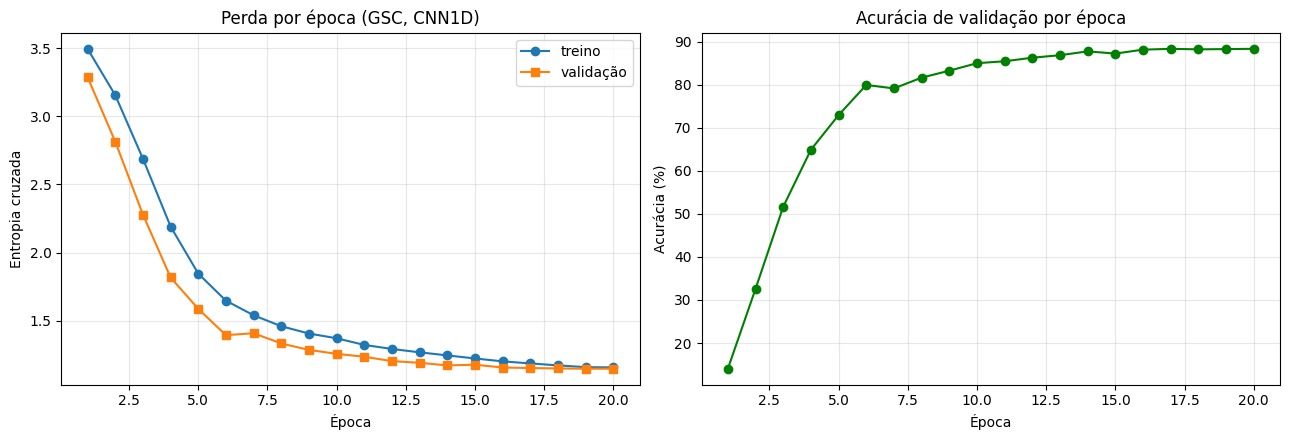

Perda final | treino: 1.1571 | val: 1.1475
Gap (val - treino): -0.0096
Acurácia final: 88.32% | melhor: 88.32% (época 17)


In [33]:
eixo_x = range(1, len(hist_base['acc']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(eixo_x, hist_base['treino'], marker='o', label='treino')
axes[0].plot(eixo_x, hist_base['val'], marker='s', label='validação')
axes[0].set_title('Perda por época (GSC, CNN1D)')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Entropia cruzada')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(eixo_x, [a * 100 for a in hist_base['acc']], marker='o', color='green')
axes[1].set_title('Acurácia de validação por época')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Acurácia (%)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

print(f'Perda final | treino: {hist_base["treino"][-1]:.4f} | val: {hist_base["val"][-1]:.4f}')
print(f'Gap (val - treino): {hist_base["gap"]:+.4f}')
print(f'Acurácia final: {hist_base["acc_final"]*100:.2f}% | melhor: {hist_base["melhor_acc"]*100:.2f}% (época {hist_base["melhor_epoca"]})')

## 6. Avaliação no teste

- **Acurácia:** fração de acertos.
- **F1 macro:** média do F1 de cada classe; pesa todas as classes igualmente.
- **Matriz de confusão:** linha = classe verdadeira, coluna = classe prevista (normalizada por linha).

In [34]:
from sklearn.metrics import confusion_matrix, f1_score


@torch.no_grad()
def prever(model, dataloader, device):
    model.eval()
    preds, reais = [], []
    for mfccs, labels in dataloader:
        preds.append(model(mfccs.to(device)).argmax(dim=1).cpu())
        reais.append(labels)
    return torch.cat(preds), torch.cat(reais)


def matriz_confusao(y_pred, y_true, n_classes):
    """Linha = classe verdadeira, coluna = classe prevista. Cada célula conta quantos áudios caíram ali."""

    #Cada par (verdadeira, prevista) vira um número único: verdadeira * n_classes + prevista.
    #Ex.: com 35 classes, (verdadeira=2, prevista=5) vira 2*35+5 = 75.
    #O bincount conta quantas vezes cada número aparece, e o view reorganiza a contagem em 35 x 35
    pares = y_true * n_classes + y_pred
    return torch.bincount(pares, minlength=n_classes ** 2).view(n_classes, n_classes)


def f1_por_classe(cm):
    cm = cm.float()
    acertos = cm.diag()                                 #a diagonal: previu certo

    #Soma da COLUNA = quantas vezes a rede previu essa classe | soma da LINHA = quantos áudios eram dela.
    #O clamp(min=1) evita dividir por zero numa classe que a rede nunca previu
    precisao = acertos / cm.sum(dim=0).clamp(min=1)     #das vezes que disse "yes", quantas eram yes?
    revocacao = acertos / cm.sum(dim=1).clamp(min=1)    #dos áudios que eram yes, quantos ela achou?

    return 2 * precisao * revocacao / (precisao + revocacao).clamp(min=1e-12)


def avaliar(model, dataloader):
    """Acurácia, F1 macro (todas as classes com o mesmo peso), matriz de confusão e F1 por classe."""
    y_pred, y_true = prever(model, dataloader, device)
    cm = matriz_confusao(y_pred, y_true, len(CLASSES_GSC))
    f1_classes = f1_por_classe(cm)

    return dict(acc=cm.diag().sum().item() / cm.sum().item(), f1_macro=f1_classes.mean().item(),
                cm=cm, f1_classes=f1_classes, y_pred=y_pred, y_true=y_true)

In [35]:
res_teste = avaliar(model_base, dm_base.test_dataloader())
print(f"teste | acurácia: {res_teste['acc']*100:.2f}% | F1 macro: {res_teste['f1_macro']:.4f}")

#Conferência contra o sklearn (só para checar, como no exercício)
from sklearn.metrics import f1_score
print('F1 macro | minha:', round(res_teste['f1_macro'], 6),
      '| sklearn:', round(f1_score(res_teste['y_true'].numpy(), res_teste['y_pred'].numpy(), average='macro'), 6))

teste | acurácia: 85.92% | F1 macro: 0.8476
F1 macro | minha: 0.847577 | sklearn: 0.847577


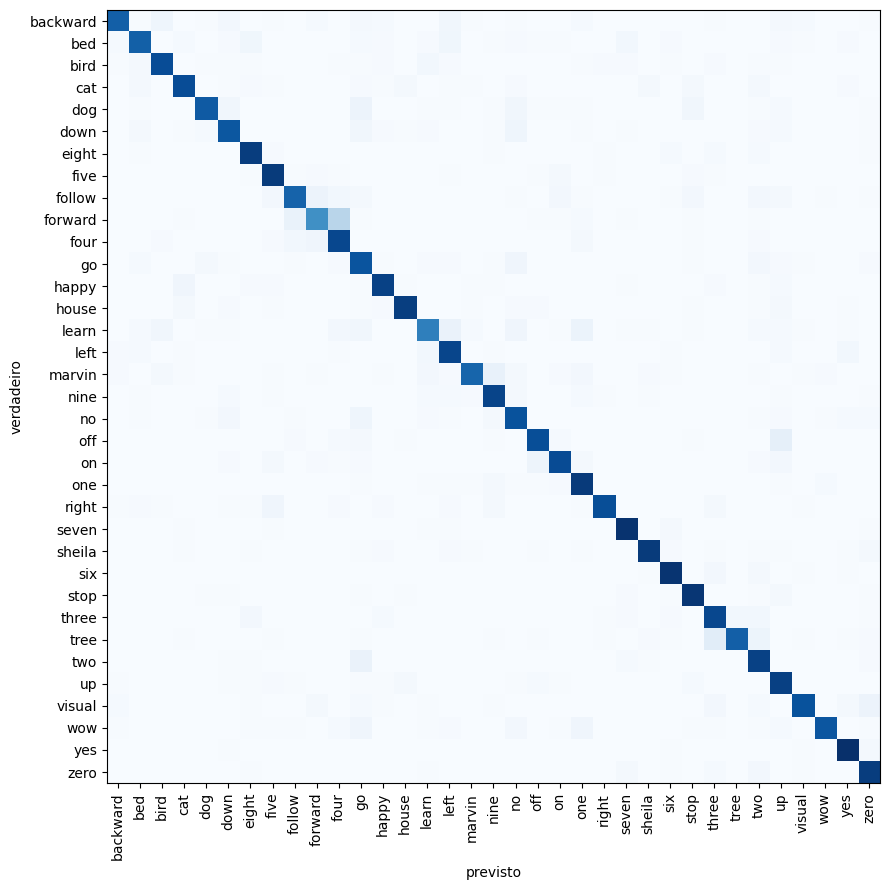

,verdadeiro,previsto,fração
0,forward,four,0.277419
1,tree,three,0.103627
2,off,up,0.082090
3,marvin,nine,0.071795
4,forward,follow,0.064516
5,learn,left,0.062112
6,two,go,0.061321
7,learn,one,0.055901
8,dog,go,0.054545
9,visual,zero,0.054545


In [36]:
cm_norm = res_teste['cm'].float() / res_teste['cm'].sum(dim=1, keepdim=True)   #normalizada por linha

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(cm_norm, cmap='Blues')
ax.set_xticks(range(len(CLASSES_GSC)), CLASSES_GSC, rotation=90)
ax.set_yticks(range(len(CLASSES_GSC)), CLASSES_GSC)
ax.set_xlabel('previsto'); ax.set_ylabel('verdadeiro')
plt.tight_layout(); plt.show()

#Pares mais confundidos (fora da diagonal): o mapa dos erros fonéticos
pares = [(CLASSES_GSC[i], CLASSES_GSC[j], cm_norm[i, j].item())
         for i in range(len(CLASSES_GSC)) for j in range(len(CLASSES_GSC)) if i != j]
display(pd.DataFrame(sorted(pares, key=lambda p: -p[2])[:10], columns=['verdadeiro', 'previsto', 'fração']))

In [37]:
#Ranking de F1 por classe na VALIDAÇÃO
res_val = avaliar(model_base, dm_base.val_dataloader())
ranking = pd.DataFrame({'palavra': CLASSES_GSC, 'f1_val': res_val['f1_classes'].numpy()})
display(ranking.sort_values('f1_val', ascending=False).reset_index(drop=True))

,palavra,f1_val
0,yes,0.959698
1,zero,0.927916
2,right,0.921541
3,seven,0.920513
4,stop,0.910663
5,eight,0.910128
6,six,0.908851
7,sheila,0.908189
8,one,0.904494
9,five,0.903846


## 7. Latência (MFCC × rede)

Protocolo da hipótese (b): CPU com **1 thread**, **batch 1** (um comando por vez, como no dispositivo),
aquecimento antes de medir e mediana de várias repetições. O MFCC e a rede são medidos separadamente.

In [38]:
import copy
import platform

In [39]:
def cronometrar(fn, repeticoes=300, aquecimento=30):
    #Aquecimento: as primeiras chamadas são mais lentas (caches vazios, alocação de memória).
    #Não entram na medida
    for _ in range(aquecimento):
        fn()

    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter()     #relógio de alta resolução, feito para medir intervalos curtos
        fn()
        tempos.append((time.perf_counter() - t0) * 1e3)    #segundos -> milissegundos

    #Mediana
    #O p95 diz "em 95% das vezes foi mais rápido que isso" 
    return float(np.median(tempos)), float(np.percentile(tempos, 95))

In [40]:
LIMITE_INSTAVEL = 0.30   #escolha minha, ajustável: (máx - mín) / mediana da razão entre as rodadas


def nome_cpu():
    """Modelo da CPU desta medida (o Colab muda de máquina entre sessões)."""
    try:
        with open('/proc/cpuinfo') as f:
            for linha in f:
                if linha.startswith('model name'):
                    return linha.split(':', 1)[1].strip()
    except OSError:
        pass   #fora do Linux (ex.: Mac) não existe /proc/cpuinfo
    return platform.processor() or 'desconhecida'


@torch.no_grad()
def medir_latencia(model, hp, media, desvio, rodadas=5, repeticoes=300, aquecimento=30, tentativas=3):
    """Mede MFCC, normalização e rede, separadamente, na CPU. Devolve um dicionário em ms."""

    #CPU com 1 thread (simula um núcleo de dispositivo de borda) e batch 1 (um comando por vez)
    threads_antes = torch.get_num_threads()
    torch.set_num_threads(1)

    try:    #sem o try/finally, um erro no meio deixaria o notebook inteiro com 1 thread
        #Cópia na CPU
        modelo_cpu = copy.deepcopy(model).cpu().eval()
        ext_cpu = criar_extrator(hp).cpu().eval()

        wav = torch.randn(1, N_AMOSTRAS) * 0.1                 # (1, 16000): um áudio de 1 s
        feat = ext_cpu(wav)                                    # (1, n_mfcc, n_frames)
        feat_norm = normalizar(feat, media, desvio)            #a entrada que a rede realmente recebe
        feat_x8 = feat_norm.repeat(8, 1, 1)                    #8 áudios iguais, para o teste de overhead

        melhor = None
        for tentativa in range(1, tentativas + 1):
            med = {'mfcc': [], 'norm': [], 'rede': [], 'rede_x8': []}
            p95 = {'mfcc': [], 'norm': [], 'rede': []}

            #As 3 etapas são medidas DENTRO de cada rodada (e não 5 rodadas de uma etapa, depois 5 de outra):
            #se a máquina ficar mais lenta no meio, o efeito cai nas 3 igualmente e a razão se preserva
            for _ in range(rodadas):
                m, p = cronometrar(lambda: ext_cpu(wav), repeticoes, aquecimento)
                med['mfcc'].append(m); p95['mfcc'].append(p)

                m, p = cronometrar(lambda: normalizar(feat, media, desvio), repeticoes, aquecimento)
                med['norm'].append(m); p95['norm'].append(p)

                m, p = cronometrar(lambda: modelo_cpu(feat_norm), repeticoes, aquecimento)
                med['rede'].append(m); p95['rede'].append(p)

                m, _ = cronometrar(lambda: modelo_cpu(feat_x8), repeticoes, aquecimento)
                med['rede_x8'].append(m)

            #A razão da hipótese (b), rodada a rodada. A variação dela entre as rodadas é o que diz se a medida é confiável
            razoes = [(a + b) / c for a, b, c in zip(med['mfcc'], med['norm'], med['rede'])]
            oscilacao = (max(razoes) - min(razoes)) / np.median(razoes)

            #Guarda a tentativa mais estável vista até agora
            if melhor is None or oscilacao < melhor['oscilacao']:
                melhor = dict(med=med, p95=p95, razoes=razoes, oscilacao=oscilacao)

            if oscilacao <= LIMITE_INSTAVEL:
                break    #estável: não precisa repetir
    finally:
        torch.set_num_threads(threads_antes)

    med, p95, razoes = melhor['med'], melhor['p95'], melhor['razoes']
    estavel = melhor['oscilacao'] <= LIMITE_INSTAVEL
    if not estavel:
        print(f'AVISO: latência instável (razão oscilou {melhor["oscilacao"]*100:.0f}% entre as rodadas, '
              f'limite {LIMITE_INSTAVEL*100:.0f}%). Rode de novo com a máquina ociosa antes de usar este número')

    mfcc_ms = float(np.median(med['mfcc']))
    norm_ms = float(np.median(med['norm']))
    rede_ms = float(np.median(med['rede']))
    rede_x8_ms = float(np.median(med['rede_x8']))

    return dict(mfcc_ms=mfcc_ms, mfcc_p95_ms=float(np.median(p95['mfcc'])),
                norm_ms=norm_ms, norm_p95_ms=float(np.median(p95['norm'])),
                rede_ms=rede_ms, rede_p95_ms=float(np.median(p95['rede'])),
                preproc_ms=mfcc_ms + norm_ms,                              #pré-processamento = MFCC + normalização
                preproc_sobre_rede=float(np.median(razoes)),               #a razão da hipótese (b)
                razao_min=min(razoes), razao_max=max(razoes),
                oscilacao=float(melhor['oscilacao']), estavel=estavel, tentativas_feitas=tentativa,
                rede_x8_ms=rede_x8_ms, fator_x8=rede_x8_ms / rede_ms,      #teste de overhead (ver abaixo)
                rodadas=rodadas, cpu=nome_cpu())

In [41]:
#Teste do medir latencia
modelo_lat = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hyperparameters['n_mfcc'],
                   n_frames=N_FRAMES, canais=hyperparameters['canais'])

lat = medir_latencia(modelo_lat, hyperparameters, datamodule.media, datamodule.desvio)

print(f"CPU: {lat['cpu']}")
print(f"MFCC: {lat['mfcc_ms']:.3f} ms (p95 {lat['mfcc_p95_ms']:.3f}) | "
      f"normalização: {lat['norm_ms']:.3f} ms (p95 {lat['norm_p95_ms']:.3f}) | "
      f"rede: {lat['rede_ms']:.3f} ms (p95 {lat['rede_p95_ms']:.3f})")
print(f"pré-processamento / rede = {lat['preproc_sobre_rede']:.2f}x "
      f"(entre {lat['razao_min']:.2f} e {lat['razao_max']:.2f} nas {lat['rodadas']} rodadas) | "
      f"estável: {lat['estavel']} (tentativas: {lat['tentativas_feitas']})")
print(f"rede com batch 8: {lat['rede_x8_ms']:.3f} ms = {lat['fator_x8']:.1f}x o tempo do batch 1")

CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
MFCC: 0.664 ms (p95 0.793) | normalização: 0.007 ms (p95 0.007) | rede: 0.423 ms (p95 0.544)
pré-processamento / rede = 1.59x (entre 1.51 e 1.66 nas 5 rodadas) | estável: True (tentativas: 1)
rede com batch 8: 1.328 ms = 3.1x o tempo do batch 1


## 8. Experimentos

In [42]:
import gc
#Libera RAM
del datamodule, dm_base, train_dl, val_dl, test_dl
gc.collect()

33870

In [43]:
resultados_tabela = []   #UMA linha por treino: configuração, validação, teste, custo e latência
modelos = {}             #modelo treinado de cada execução: (experimento, seed) -> model
hists = {}               #curvas de cada treino: (experimento, seed) -> hist
latencias = {}           #uma medida por CONFIGURAÇÃO: experimento -> dicionário da medir_latencia

In [44]:
mfcc_em_memoria = {'nome': nome_cache(hyperparameters), 'dados': dados}   

def carregar_dados(hp):
    nome = nome_cache(hp)

    #Só recarrega se a configuração do MFCC mudou desde o experimento anterior
    if mfcc_em_memoria['nome'] != nome:
        #Solta o MFCC antigo ANTES de carregar o novo
        mfcc_em_memoria['dados'] = None

        extrator = criar_extrator(hp)
        dados_novos = {}
        for nome_split, arquivos in split.items():
            caminho = os.path.join(PASTA_CACHE, f'gsc_{nome_split}_{nome}.pt')
            dados_novos[nome_split] = extrair_mfcc(arquivos, caminho, extrator, CLASSES_GSC)

        mfcc_em_memoria['nome'] = nome
        mfcc_em_memoria['dados'] = dados_novos

    return mfcc_em_memoria['dados']

In [45]:
def registrar(nome, seed, hp, hist, teste):
    """Acrescenta uma linha à tabela de resultados."""

    #Custo medido num modelo NOVO: o custo() roda um forward em modo train(), e isso alteraria as
    #estatísticas acumuladas do BatchNorm do modelo treinado. Parâmetros e MACs não dependem dos pesos
    modelo_novo = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hp['n_mfcc'],
                        n_frames=calcular_n_frames(hp), canais=hp['canais'])
    c = custo(modelo_novo, hp['n_mfcc'], calcular_n_frames(hp))

    resultados_tabela.append({
        'experimento': nome, 'seed': seed, 'fracao': hp['fracao'], 'epocas': hp['epocas'],
        'spec_augment': hp['spec_augment'], 'normalizacao': hp['normalizacao'],
        'weight_decay': hp['weight_decay'], 'canais': hp['canais'],
        'entrada': f"{hp['n_mfcc']}x{calcular_n_frames(hp)}",
        'params': c['params'], 'kb_int8': round(c['kb_int8'], 1), 'macs': c['macs'],
        'acc_val': hist['melhor_acc'],            #melhor acurácia de VALIDAÇÃO (a que seleciona)
        'melhor_epoca': hist['melhor_epoca'], 'gap': hist['gap'], 'tempo_min': hist['tempo_min'],
        'acc_teste': teste['acc'], 'f1_teste': teste['f1_macro'],    #só para reportar: nada é escolhido com elas
    })

In [ ]:
FRACAO = hyperparameters['fracao'] 
SEEDS = hyperparameters['seeds']

configs_experimentos = [
    ('baseline',                 {}),
    ('sem spec_augment',         {'spec_augment': False}),
    ('norm por_amostra',         {'normalizacao': 'por_amostra'}),
    ('sem weight_decay',         {'weight_decay': 0.0}),
    ('canais 32',                {'canais': 32}),
    ('canais 16',                {'canais': 16}),
    ('canais 8',                 {'canais': 8}),
    ('canais 4',                 {'canais': 4}),
    ('entrada hello_edge',       {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False}),
    ('hello_edge + canais 16',   {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'canais': 16}),
    ('hello_edge + canais 8',    {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'canais': 8}),
    ('hello_edge + canais 48',   {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'canais': 48}),
    ('hello_edge + canais 32',   {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'canais': 32}),
]

ja_feitos = {(r['experimento'], r['seed'], r['fracao']) for r in resultados_tabela}

#Seed por fora: se algo falhar no meio, o que já terminou é uma comparação COMPLETA com a seed 0
for seed in SEEDS:
    barra = tqdm(configs_experimentos, desc=f'seed {seed}')    
    for nome, mudancas in barra:
        barra.set_postfix_str(nome)                            
        hp = {**hyperparameters, **mudancas, 'fracao': FRACAO, 'seed': seed}

        if (nome, seed, FRACAO) in ja_feitos:
            print(f'{nome} (seed {seed}): já está na tabela, pulando')
            continue

        model, hist, dm = rodar_experimento(hp, carregar_dados(hp), nome=f'{nome} s{seed}', verbose=False)

        #Teste medido logo depois do treino: sem checkpoint, os pesos não sobrevivem à sessão
        teste = avaliar(model, dm.test_dataloader())

        registrar(nome, seed, hp, hist, teste)
        modelos[(nome, seed)] = model
        hists[(nome, seed)] = hist
        del dm    #libera as cópias normalizadas dos dados 

baseline s0                    | canais= 64 | melhor acc val=88.56% (época 20) | 0.6 min
sem spec_augment s0            | canais= 64 | melhor acc val=87.68% (época 16) | 0.3 min
norm por_amostra s0            | canais= 64 | melhor acc val=89.51% (época 20) | 0.6 min
sem weight_decay s0            | canais= 64 | melhor acc val=88.53% (época 20) | 0.6 min
canais 32 s0                   | canais= 32 | melhor acc val=84.71% (época 19) | 0.5 min
canais 16 s0                   | canais= 16 | melhor acc val=75.97% (época 20) | 0.6 min
canais 8 s0                    | canais=  8 | melhor acc val=56.85% (época 20) | 0.5 min
canais 4 s0                    | canais=  4 | melhor acc val=26.85% (época 20) | 0.5 min


gsc_treino_gsc35_10x49_40-20msnc.pt:   0%|          | 0/332 [00:00<?, ?it/s]

gsc_val_gsc35_10x49_40-20msnc.pt:   0%|          | 0/39 [00:00<?, ?it/s]

gsc_teste_gsc35_10x49_40-20msnc.pt:   0%|          | 0/43 [00:00<?, ?it/s]

entrada hello_edge s0          | canais= 64 | melhor acc val=89.72% (época 18) | 0.5 min
hello_edge + canais 16 s0      | canais= 16 | melhor acc val=75.72% (época 19) | 0.5 min
hello_edge + canais 8 s0       | canais=  8 | melhor acc val=55.25% (época 18) | 0.5 min


In [ ]:
#Aquecimento descartado: no piloto, a primeira medida depois da varredura saiu inflada
#(baseline: MFCC 0,83 ms contra ~0,67 ms nas configurações com o mesmo MFCC)
hp_aq = {**hyperparameters, 'seed': SEEDS[0]}
modelo_aq = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hp_aq['n_mfcc'],
                  n_frames=calcular_n_frames(hp_aq), canais=hp_aq['canais'])
_ = medir_latencia(modelo_aq, hp_aq, torch.zeros(hp_aq['n_mfcc'], 1), torch.ones(hp_aq['n_mfcc'], 1), rodadas=2)

medidas = {}    #experimento -> uma medida por passada
ordem = list(configs_experimentos)

#2 passadas, a segunda na ordem INVERSA: se a máquina ficar mais lenta (ou mais rápida) com o tempo,
#a deriva pesa de um lado numa passada e do outro na seguinte, e a média das duas compensa
for passada in range(2):
    for nome, mudancas in ordem:
        hp = {**hyperparameters, **mudancas, 'fracao': FRACAO, 'seed': SEEDS[0]}

        if hp['normalizacao'] == 'global':
            media = torch.zeros(hp['n_mfcc'], 1)    #o tempo não depende dos valores, só do formato
            desvio = torch.ones(hp['n_mfcc'], 1)
        else:
            media = desvio = None                   #por_amostra: calcula média e desvio de cada áudio

        model_lat = CNN1D(n_classes=len(CLASSES_GSC), n_mfcc=hp['n_mfcc'],
                          n_frames=calcular_n_frames(hp), canais=hp['canais'])

        if nome not in medidas:
            medidas[nome] = []
        medidas[nome].append(medir_latencia(model_lat, hp, media, desvio))
    ordem = ordem[::-1]

latencias = {}
colunas_numericas = ['mfcc_ms', 'norm_ms', 'rede_ms', 'preproc_ms', 'preproc_sobre_rede', 'fator_x8']
for nome, lista in medidas.items():
    latencias[nome] = dict(lista[0])                       #cpu e os outros campos
    for coluna in colunas_numericas:
        latencias[nome][coluna] = float(np.mean([m[coluna] for m in lista]))
    latencias[nome]['estavel'] = all(m['estavel'] for m in lista)

    l = latencias[nome]
    print(f"{nome:26s} | MFCC {l['mfcc_ms']:.3f} ms | norm {l['norm_ms']:.3f} ms | rede {l['rede_ms']:.3f} ms | "
          f"preproc/rede {l['preproc_sobre_rede']:.2f}x | estável: {l['estavel']} | "
          f"rede nas 2 passadas: {lista[0]['rede_ms']:.3f} / {lista[1]['rede_ms']:.3f}")

#Todas as latências precisam sair da MESMA máquina: o Colab muda de CPU entre sessões
cpus = {l['cpu'] for l in latencias.values()}
if len(cpus) > 1:
    print('AVISO: as medidas vieram de CPUs diferentes:', cpus)
else:
    print('CPU (todas as medidas):', cpus.pop())

#Anexa a latência a TODAS as linhas da tabela única (a latência é da configuração, igual para todas as seeds)
colunas_lat = ['mfcc_ms', 'norm_ms', 'rede_ms', 'preproc_ms', 'preproc_sobre_rede', 'fator_x8', 'estavel', 'cpu']
for linha in resultados_tabela:
    for coluna in colunas_lat:
        linha[coluna] = latencias[linha['experimento']][coluna]

baseline                   | MFCC 0.831 ms | norm 0.011 ms | rede 0.622 ms | preproc/rede 1.47x | x8: 3.1x | estável: True
sem spec_augment           | MFCC 0.682 ms | norm 0.007 ms | rede 0.441 ms | preproc/rede 1.51x | x8: 3.2x | estável: True
norm por_amostra           | MFCC 0.676 ms | norm 0.066 ms | rede 0.448 ms | preproc/rede 1.66x | x8: 3.0x | estável: True
sem weight_decay           | MFCC 0.665 ms | norm 0.007 ms | rede 0.446 ms | preproc/rede 1.54x | x8: 3.1x | estável: True
canais 32                  | MFCC 0.702 ms | norm 0.007 ms | rede 0.374 ms | preproc/rede 1.88x | x8: 2.9x | estável: True
canais 16                  | MFCC 0.677 ms | norm 0.007 ms | rede 0.319 ms | preproc/rede 2.08x | x8: 3.0x | estável: True
canais 8                   | MFCC 0.692 ms | norm 0.007 ms | rede 0.302 ms | preproc/rede 2.30x | x8: 2.8x | estável: True
canais 4                   | MFCC 0.902 ms | norm 0.011 ms | rede 0.419 ms | preproc/rede 2.18x | x8: 2.9x | estável: True
entrada hello_ed

## 9. Resumo da tentativa

In [48]:
def montar_resumo(fracao):
    df = pd.DataFrame(resultados_tabela)
    if 'mfcc_ms' not in df.columns:
        raise RuntimeError('Rode a célula da latência (capítulo 8, célula 5) antes do resumo')
    df = df[df['fracao'] == fracao]

    resumo = df.groupby('experimento', sort=False).agg(
        runs=('seed', 'count'),
        acc_val=('acc_val', 'mean'), acc_val_dp=('acc_val', 'std'),
        acc_teste=('acc_teste', 'mean'), acc_teste_dp=('acc_teste', 'std'),
        f1_teste=('f1_teste', 'mean'), f1_teste_dp=('f1_teste', 'std'),
        entrada=('entrada', 'first'), params=('params', 'first'), kb_int8=('kb_int8', 'first'), macs=('macs', 'first'),
        mfcc_ms=('mfcc_ms', 'first'), norm_ms=('norm_ms', 'first'), rede_ms=('rede_ms', 'first'),
        preproc_sobre_rede=('preproc_sobre_rede', 'first'), fator_x8=('fator_x8', 'first'),
        tempo_min=('tempo_min', 'mean'))

    for coluna in ['acc_val', 'acc_val_dp', 'acc_teste', 'acc_teste_dp', 'f1_teste', 'f1_teste_dp']:
        resumo[coluna] = resumo[coluna] * 100     #em %. O desvio fica NaN com 1 seed: normal

    #Critério definido ANTES de ver os resultados, medido na VALIDAÇÃO
    resumo['dif_baseline'] = resumo['acc_val'] - resumo.loc['baseline', 'acc_val']
    resumo['dentro_2pp'] = resumo['dif_baseline'] >= -hyperparameters['margem_pp']    
    return resumo


def formatar(media, dp):
    if pd.isna(dp):
        return f'{media:.2f}'
    return f'{media:.2f} ± {dp:.2f}'


resumo = montar_resumo(FRACAO)

In [49]:
#Todos os treinos, um por linha
colunas_runs = ['experimento', 'seed', 'entrada', 'canais', 'params', 'macs', 'acc_val', 'melhor_epoca', 'gap',
                'acc_teste', 'f1_teste', 'mfcc_ms', 'rede_ms', 'tempo_min']
df_runs = pd.DataFrame(resultados_tabela)
display(df_runs[df_runs['fracao'] == FRACAO][colunas_runs].round(4))

,experimento,seed,entrada,canais,params,macs,acc_val,melhor_epoca,gap,acc_teste,f1_teste,mfcc_ms,rede_ms,tempo_min
0,baseline,0,40x101,64,47331,1883840,0.8856,20,-0.0084,0.8626,0.8503,0.8311,0.6218,0.6364
1,sem spec_augment,0,40x101,64,47331,1883840,0.8768,16,0.2512,0.8499,0.8355,0.6823,0.4407,0.3461
2,norm por_amostra,0,40x101,64,47331,1883840,0.8951,20,0.0379,0.8841,0.8726,0.6761,0.4485,0.6392
3,sem weight_decay,0,40x101,64,47331,1883840,0.8853,20,-0.0127,0.8644,0.8526,0.6645,0.4461,0.6350
4,canais 32,0,40x101,32,14467,665440,0.8471,19,-0.1151,0.8183,0.7982,0.7017,0.3741,0.5373
5,canais 16,0,40x101,16,4947,263600,0.7597,20,-0.1908,0.7333,0.6943,0.6772,0.3191,0.5578
6,canais 8,0,40x101,8,1915,114520,0.5685,20,-0.1504,0.5480,0.4873,0.6917,0.3018,0.5360
7,canais 4,0,40x101,4,831,52940,0.2685,20,-0.0562,0.2658,0.1637,0.9021,0.4191,0.5386
8,entrada hello_edge,0,10x49,64,41571,649280,0.8972,18,-0.1370,0.8781,0.8670,0.5024,0.3763,0.5200
9,hello_edge + canais 16,0,10x49,16,3507,58640,0.7572,19,-0.3135,0.7270,0.6889,0.5118,0.2985,0.4761


In [50]:
#Resumo por experimento (média ± desvio entre as seeds): a tabela dos slides
slide = pd.DataFrame({
    'Entrada': resumo['entrada'],
    'Params': resumo['params'],
    'KB int8': resumo['kb_int8'],
    'MACs': resumo['macs'],
    'Acc val (%)': [formatar(m, d) for m, d in zip(resumo['acc_val'], resumo['acc_val_dp'])],
    'Acc teste (%)': [formatar(m, d) for m, d in zip(resumo['acc_teste'], resumo['acc_teste_dp'])],
    'F1 teste (%)': [formatar(m, d) for m, d in zip(resumo['f1_teste'], resumo['f1_teste_dp'])],
    'MFCC (ms)': resumo['mfcc_ms'].round(3),
    'Rede (ms)': resumo['rede_ms'].round(3),
    'Pré-proc / rede': resumo['preproc_sobre_rede'].round(2),
    'Dif. val vs baseline (p.p.)': resumo['dif_baseline'].round(2),
    'Dentro de 2 p.p.': resumo['dentro_2pp'],
})
display(slide)

aprovados = resumo[resumo['dentro_2pp']].sort_values(['params', 'macs'])
print(f"Menor modelo dentro de 2 p.p. do baseline: {aprovados.index[0]} "
      f"({aprovados.iloc[0]['params']:,.0f} parâmetros, {aprovados.iloc[0]['macs']:,.0f} MACs)")
if resumo['runs'].max() < 3:
    print('ATENÇÃO: com menos de 3 seeds isto é só um palpite, não uma conclusão')

,Entrada,Params,KB int8,MACs,Acc val (%),Acc teste (%),F1 teste (%),MFCC (ms),Rede (ms),Pré-proc / rede,Dif. val vs baseline (p.p.),Dentro de 2 p.p.
experimento,,,,,,,,,,,,
baseline,40x101,47331,46.2,1883840,88.56,86.26,85.03,0.831,0.622,1.47,0.00,True
sem spec_augment,40x101,47331,46.2,1883840,87.68,84.99,83.55,0.682,0.441,1.51,-0.88,True
norm por_amostra,40x101,47331,46.2,1883840,89.51,88.41,87.26,0.676,0.448,1.66,0.95,True
sem weight_decay,40x101,47331,46.2,1883840,88.53,86.44,85.26,0.665,0.446,1.54,-0.03,True
canais 32,40x101,14467,14.1,665440,84.71,81.83,79.82,0.702,0.374,1.88,-3.85,False
canais 16,40x101,4947,4.8,263600,75.97,73.33,69.43,0.677,0.319,2.08,-12.58,False
canais 8,40x101,1915,1.9,114520,56.85,54.80,48.73,0.692,0.302,2.30,-31.71,False
canais 4,40x101,831,0.8,52940,26.85,26.58,16.37,0.902,0.419,2.18,-61.71,False
entrada hello_edge,10x49,41571,40.6,649280,89.72,87.81,86.70,0.502,0.376,1.37,1.16,True


Menor modelo dentro de 2 p.p. do baseline: entrada hello_edge (41,571 parâmetros, 649,280 MACs)
ATENÇÃO: com menos de 3 seeds isto é só um palpite, não uma conclusão


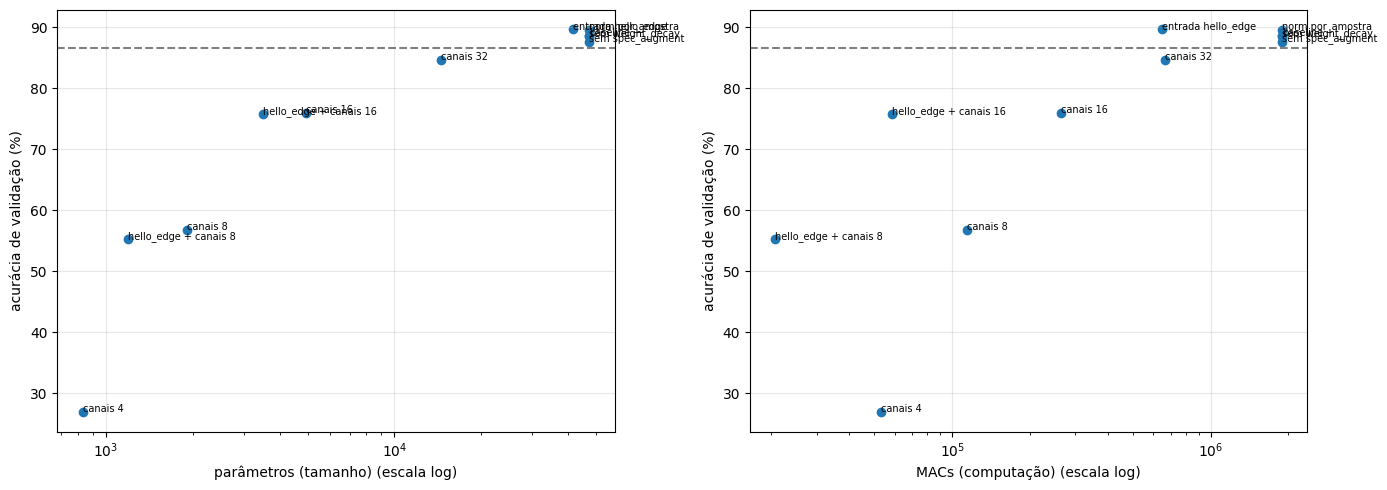

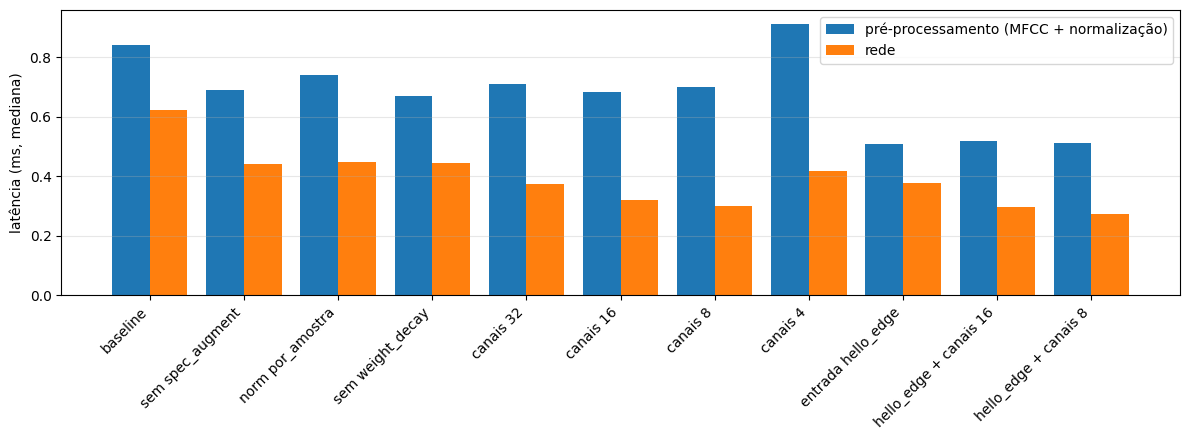

In [51]:
#Acurácia x custo, com o piso do critério de 2 p.p.
limite = resumo.loc['baseline', 'acc_val'] - hyperparameters['margem_pp']          
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, coluna, titulo in [(axes[0], 'params', 'parâmetros (tamanho)'), (axes[1], 'macs', 'MACs (computação)')]:
    ax.scatter(resumo[coluna], resumo['acc_val'])
    for nome, linha in resumo.iterrows():
        ax.annotate(nome, (linha[coluna], linha['acc_val']), fontsize=7)
    ax.axhline(limite, linestyle='--', color='gray')     #o piso do critério de 2 p.p.
    ax.set_xscale('log')
    ax.set_xlabel(f'{titulo} (escala log)'); ax.set_ylabel('acurácia de validação (%)')
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

#Hipótese (b): pré-processamento x rede
fig, ax = plt.subplots(figsize=(12, 4.5))
posicao = np.arange(len(resumo))
ax.bar(posicao - 0.2, resumo['mfcc_ms'] + resumo['norm_ms'], width=0.4, label='pré-processamento (MFCC + normalização)')
ax.bar(posicao + 0.2, resumo['rede_ms'], width=0.4, label='rede')
ax.set_xticks(posicao, resumo.index, rotation=45, ha='right')
ax.set_ylabel('latência (ms, mediana)'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

## 10. Levando para o repositório

Quando a arquitetura estiver definida:
1. Copie a classe para `modelos/cnn1d.py`, no lugar do esqueleto, com o decorador `@registrar_modelo(...)` que
   já está lá, e mude `IMPLEMENTADO = True`.
2. Passe os valores de `hp_modelo` para `configs/cnn1d.yaml` (seção `modelo:`), e o que mudou em
   `hyperparameters` (épocas, learning rate...) também.
3. Rode `pytest` para conferir o contrato.
4. Rode o `template_modelo.ipynb` com o seu modelo e confira se os números batem com os daqui (com `fracao = 1.0`).
